# Customer Churn Prediction — An Illustrative Pipeline

This notebook walks through a small, end-to-end pipeline for developing a customer churn prediction model:

1. **Load** the data
2. **Clean** the data (impute missing values)
3. **Transform** the data (dummy encoding of categorical variables)
4. **Model**: fit a Linear Regression and a Logistic Regression on the churn indicator
5. **Evaluate** both models on accuracy and AUC

### Dataset
We use the well-known **IBM Telco Customer Churn** dataset: 7,043 customers of a telecom company, with a `Churn` (Yes/No) column as the target. It is small, clean, mixes numeric and categorical variables, and contains a handful of genuine missing values — which makes it a good teaching dataset for exactly this pipeline.

- Source used below: `https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv`
- Mirror (if the link above ever moves): search Kaggle for **"Telco Customer Churn" (blastchar)** — it's the same dataset.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score, roc_curve

RANDOM_STATE = 42
pd.set_option('display.max_columns', None)

## 1. Load the data

In [2]:
DATA_URL = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"

df = pd.read_csv(DATA_URL)

print(f"Shape: {df.shape}")
df.head()

Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


## 2. Clean the data — impute missing values

`TotalCharges` is loaded as text because a handful of brand-new customers (`tenure == 0`) have an empty string instead of a number. Converting the column to numeric turns those blanks into proper, detectable missing values (`NaN`) that we can then impute — this mirrors the situation you'll run into with most real-world business datasets.

In [3]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

missing = df.isna().sum()
print("Missing values per column:")
print(missing[missing > 0])

Missing values per column:
TotalCharges    11
dtype: int64


In [5]:
# Drop the customer identifier (not a predictive feature) and encode the target as 0/1
df = df.drop(columns=['customerID'])
df['Churn'] = df['Churn'].map({'No': 0, 'Yes': 1})

numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns.drop('Churn')
categorical_cols = df.select_dtypes(include=['object']).columns

print("Numeric columns:", list(numeric_cols))
print("Categorical columns:", list(categorical_cols))

Numeric columns: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical columns: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [6]:
# Impute: median for numeric columns, most-frequent category for categorical columns.
# This general pattern works even if a dataset has missing categorical values too.
num_imputer = SimpleImputer(strategy='median')
df[numeric_cols] = num_imputer.fit_transform(df[numeric_cols])

cat_imputer = SimpleImputer(strategy='most_frequent')
df[categorical_cols] = cat_imputer.fit_transform(df[categorical_cols])

print("Missing values remaining:", df.isna().sum().sum())

Missing values remaining: 0


## 3. Transform the data — dummy encoding of categorical variables

Linear and logistic regression need numeric input, so each categorical column is expanded into 0/1 dummy columns with `pd.get_dummies`. We drop one category per variable (`drop_first=True`) to avoid the [dummy variable trap](https://en.wikipedia.org/wiki/Multicollinearity) (perfect multicollinearity between the dummies).

In [7]:
df_encoded = pd.get_dummies(df, columns=list(categorical_cols), drop_first=True)

print(f"Shape after dummy encoding: {df_encoded.shape}")
df_encoded.head()

Shape after dummy encoding: (7043, 31)


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,InternetService_Fiber optic,InternetService_No,OnlineSecurity_No internet service,OnlineSecurity_Yes,OnlineBackup_No internet service,OnlineBackup_Yes,DeviceProtection_No internet service,DeviceProtection_Yes,TechSupport_No internet service,TechSupport_Yes,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0.0,1.0,29.85,29.85,0,False,True,False,False,True,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,True,False,True,False
1,0.0,34.0,56.95,1889.50,0,True,False,False,True,False,False,False,False,False,True,False,False,False,True,False,False,False,False,False,False,True,False,False,False,False,True
2,0.0,2.0,53.85,108.15,1,True,False,False,True,False,False,False,False,False,True,False,True,False,False,False,False,False,False,False,False,False,False,True,False,False,True
3,0.0,45.0,42.30,1840.75,0,True,False,False,False,True,False,False,False,False,True,False,False,False,True,False,True,False,False,False,False,True,False,False,False,False,False
4,0.0,2.0,70.70,151.65,1,False,False,False,True,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,True,False


## 4. Train/test split

In [8]:
X = df_encoded.drop(columns=['Churn'])
y = df_encoded['Churn']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

print(f"Train size: {X_train.shape[0]}   Test size: {X_test.shape[0]}")
print(f"Churn rate — train: {y_train.mean():.3f}   test: {y_test.mean():.3f}")

Train size: 5634   Test size: 1409
Churn rate — train: 0.265   test: 0.265


## 5. Scale the features

We standardize *every* column — the numeric features and the 0/1 dummy columns alike — to zero mean and unit variance. Besides helping logistic regression converge faster, this has a second benefit we'll use later: once every feature is on the same scale, each fitted coefficient is automatically the effect of a *1-standard-deviation* change in that feature, so coefficients are directly comparable across features without any further rescaling (Section 9).

The scaler is fit on the training data only, then applied to the test data, to avoid leaking test-set information.

In [9]:
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index
)
X_test_scaled = pd.DataFrame(
    scaler.transform(X_test), columns=X_test.columns, index=X_test.index
)

## 6. Linear Regression

Linear regression treats the 0/1 churn indicator as a continuous target (a *linear probability model*). It is not designed for classification — its predictions aren't bounded between 0 and 1 — but fitting it here is instructive: it gives us a natural baseline to compare against logistic regression.

In [10]:
lin_reg = LinearRegression()
lin_reg.fit(X_train_scaled, y_train)

# Raw, unbounded predictions
y_pred_lin_continuous = lin_reg.predict(X_test_scaled)

# Threshold at 0.5 to get a class prediction, for accuracy
y_pred_lin_class = (y_pred_lin_continuous >= 0.5).astype(int)

lin_accuracy = accuracy_score(y_test, y_pred_lin_class)
# AUC only needs a score that ranks observations correctly, so the
# unbounded continuous predictions can be used directly here
lin_auc = roc_auc_score(y_test, y_pred_lin_continuous)

print(f"Linear Regression   — Accuracy: {lin_accuracy:.3f}   AUC: {lin_auc:.3f}")

Linear Regression   — Accuracy: 0.796   AUC: 0.830


## 7. Logistic Regression

Logistic regression models the log-odds of churn as a linear function of the features, which keeps predicted probabilities in [0, 1] — the natural choice for a binary target.

In [11]:
log_reg = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
log_reg.fit(X_train_scaled, y_train)

y_pred_log_class = log_reg.predict(X_test_scaled)
y_pred_log_proba = log_reg.predict_proba(X_test_scaled)[:, 1]

log_accuracy = accuracy_score(y_test, y_pred_log_class)
log_auc = roc_auc_score(y_test, y_pred_log_proba)

print(f"Logistic Regression — Accuracy: {log_accuracy:.3f}   AUC: {log_auc:.3f}")

Logistic Regression — Accuracy: 0.807   AUC: 0.842


## 8. Compare the two models

In [12]:
results = pd.DataFrame({
    'Model': ['Linear Regression', 'Logistic Regression'],
    'Accuracy': [lin_accuracy, log_accuracy],
    'AUC': [lin_auc, log_auc],
})
results

,Model,Accuracy,AUC
0,Linear Regression,0.796309,0.829799
1,Logistic Regression,0.806955,0.841585


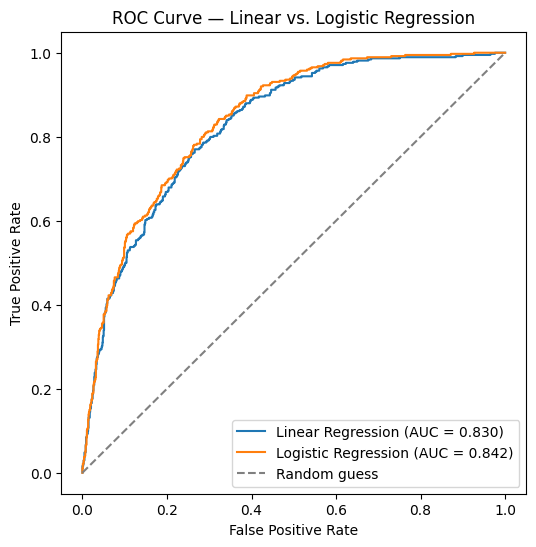

In [13]:
fpr_lin, tpr_lin, _ = roc_curve(y_test, y_pred_lin_continuous)
fpr_log, tpr_log, _ = roc_curve(y_test, y_pred_log_proba)

plt.figure(figsize=(6, 6))
plt.plot(fpr_lin, tpr_lin, label=f"Linear Regression (AUC = {lin_auc:.3f})")
plt.plot(fpr_log, tpr_log, label=f"Logistic Regression (AUC = {log_auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle='--', color='grey', label='Random guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve — Linear vs. Logistic Regression')
plt.legend()
plt.show()

## 9. Interpreting the models — ranking variables by importance

Because every feature was standardized before fitting (Section 5), the fitted coefficients are already on one common scale: each one is the effect of a *1-standard-deviation* change in that feature — the numeric features and the 0/1 dummy columns alike — on the outcome (linear regression) or on the log-odds of churn (logistic regression). That means we can rank variables by the raw coefficient magnitude directly, with no further rescaling needed.

For logistic regression we additionally convert each coefficient into an **odds ratio** (`exp(coefficient)`), which is usually the easiest way to talk about the effect in business terms: an odds ratio of 1.4 means a 1-SD increase in that feature multiplies the odds of churn by 1.4×; an odds ratio below 1 means it lowers the odds. For a 0/1 dummy, note that "a 1-SD change" means a shift in *how common* that attribute is across customers (its std is √(p·(1−p))), not a full switch from 0 to 1 — worth keeping in mind when interpreting a dummy variable's effect specifically.

In [14]:
coef_table = pd.DataFrame({
    'Feature': X.columns,
    'Linear coef. (standardized)': lin_reg.coef_,
    'Logistic coef. (standardized, log-odds)': log_reg.coef_[0],
})
coef_table['Odds ratio per 1-SD change'] = np.exp(coef_table['Logistic coef. (standardized, log-odds)'])

# Rank by the size of the standardized logistic coefficient — i.e. how much
# a 1-SD change in the feature moves the log-odds of churn, up or down
coef_table['Abs. importance (logistic)'] = coef_table['Logistic coef. (standardized, log-odds)'].abs()
coef_table = coef_table.sort_values('Abs. importance (logistic)', ascending=False).reset_index(drop=True)

top_n = 15
coef_table.drop(columns='Abs. importance (logistic)').head(top_n)

,Feature,Linear coef. (standardized),"Logistic coef. (standardized, log-odds)",Odds ratio per 1-SD change
0,tenure,-0.035442,-1.219639,0.295337
1,MonthlyCharges,-0.225114,-0.921369,0.397974
2,InternetService_Fiber optic,0.184629,0.778760,2.178770
3,Contract_Two year,-0.032142,-0.588975,0.554896
4,TotalCharges,-0.110952,0.497246,1.644187
5,Contract_One year,-0.044320,-0.286473,0.750907
6,StreamingMovies_Yes,0.063382,0.258653,1.295184
7,StreamingTV_Yes,0.063354,0.258042,1.294393
8,MultipleLines_Yes,0.046294,0.216356,1.241545
9,PaperlessBilling_Yes,0.023802,0.181833,1.199414


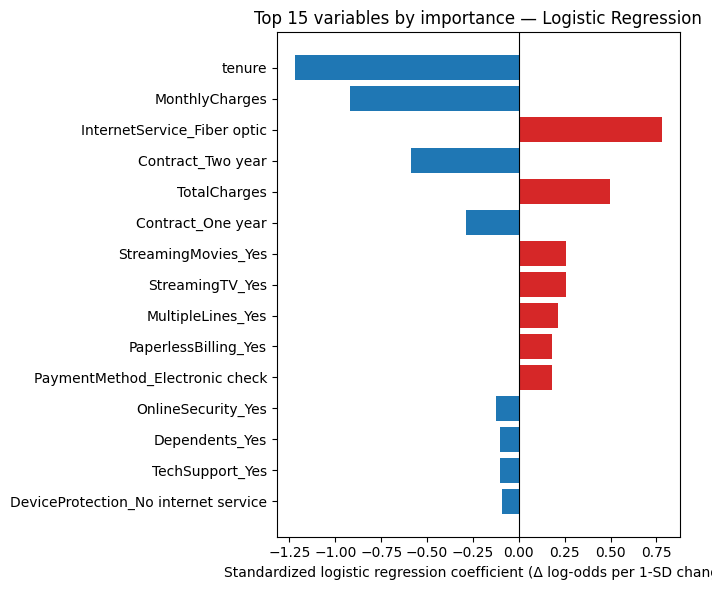

In [15]:
top = coef_table.head(top_n).iloc[::-1]  # reverse so the most important feature plots on top
colors = ['#d62728' if v > 0 else '#1f77b4' for v in top['Logistic coef. (standardized, log-odds)']]

plt.figure(figsize=(7, 6))
plt.barh(top['Feature'], top['Logistic coef. (standardized, log-odds)'], color=colors)
plt.axvline(0, color='black', linewidth=0.8)
plt.xlabel('Standardized logistic regression coefficient (Δ log-odds per 1-SD change)')
plt.title(f'Top {top_n} variables by importance — Logistic Regression')
plt.tight_layout()
plt.show()

A couple of caveats worth flagging (especially with a dummy-encoded dataset like this one):

- **These are coefficients from a single model fit, not causal effects.** Many of the dummy variables here are correlated with each other (e.g. `InternetService_No` implies `OnlineSecurity_No internet service`, `TechSupport_No internet service`, etc.), so a coefficient partly reflects *other correlated features being held fixed* rather than an isolated, actionable effect. Treat the ranking as a description of association, not a recommendation for which lever to pull.
- **Regularization helps when features are correlated.** If you need a more stable ranking, refit with `LogisticRegression(penalty='l2', C=...)` (or `'l1'` for a sparser model) and compare — coefficient rankings that survive regularization are usually more trustworthy.
- **Statistical significance is a separate question from importance.** A library like `statsmodels` (`sm.Logit(...).fit()`) will also give you standard errors, p-values, and confidence intervals for each coefficient, which this scikit-learn-based pipeline does not.

## Wrap-up

Both models produce a ranking of customers by churn risk (comparable AUC), but only logistic regression produces predictions that behave like probabilities — which matters as soon as you want to act on the scores (e.g. rank customers for a retention campaign, or set a business-driven decision threshold instead of the default 0.5). This is why logistic regression, not linear regression, is the standard choice for binary classification, and why linear regression was included above mainly for illustration and comparison.

Natural next steps for a real project:
- Handle class imbalance (the churn rate is well under 50%) with class weights or resampling.
- Try regularization (`LogisticRegression(penalty=...)`) or other classifiers (trees, gradient boosting) as benchmarks.
- Validate the coefficient-based ranking above with `statsmodels` (for significance) and/or a model-agnostic importance method (e.g. permutation importance, SHAP) to see whether the story holds up.
- Replace the default 0.5 threshold with one chosen from the actual costs and benefits of retention actions (a cost- or profit-driven cutoff), rather than a purely statistical one.